# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name: Ritika Lund**
- **Student ID: 023-24-0262**
- **Section: H**
- **GitHub: https://github.com/Ritika-Lund**
- **Kaggle: https://www.kaggle.com/ritikalund**
- **Dataset:** Mall Customers (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

### Before You Start
- This lab does not reteach K-Means. It makes you use and test what you saw in the lecture. Each task gives the steps, not the code; the **Key definitions** table in each Part lists what you need.
- There is **no target column**: no train/test split and no accuracy. Judge every result by distances, silhouette, plots and common sense.
- Use `SEED = 42` everywhere. Write 1–3 lines of interpretation under every table and plot. A plot without an explanation earns no marks.
- Place `Mall_Customers.csv` in the same folder as this notebook (or upload it to Colab).
- Time: about 2 hours 15 minutes of work. Use the remaining time to finish answers, run the notebook top to bottom and submit.

---

## Part 0 — Setup and First Look (10 minutes)

Load the data and look at it before you cluster anything.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |

**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.

In [2]:
# YOUR CODE HERE
df = pd.read_csv('Mall Customer Segmentation Dataset/Mall_Customers.csv')
df = df.rename(columns={'Annual Income (k$)': 'Income',
                        'Spending Score (1-100)': 'Spending'})

print('Shape:', df.shape)
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print(df['Gender'].value_counts())

df[['Age', 'Income', 'Spending']].describe()

Shape: (200, 5)
Missing values: 0
Duplicate rows: 0
Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


The data is clean, with 200 customers and no missing or duplicate rows (112 Female,
88 Male). Income runs from 15 to 137 k$ (mean 60.6) and Spending from 1 to 99
(mean 50.2), on similar scales. Age (18 to 70, mean 38.9) is not used in the main
clustering.

### Task 0.2 — Look at the data before clustering

Use your eyes first.

1. Draw one scatter plot of Spending vs Income, with axis labels and a title.

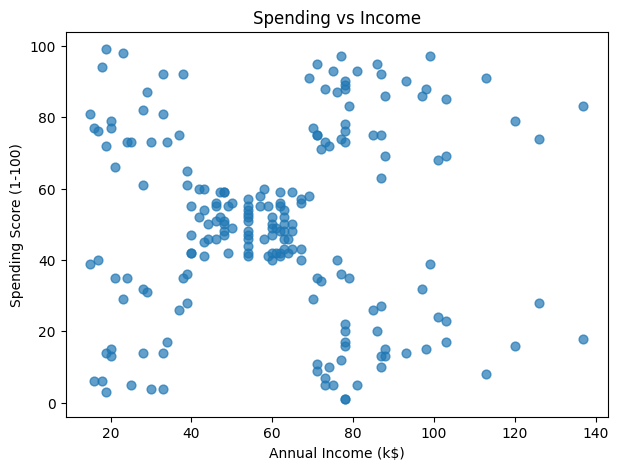

In [3]:
# YOUR CODE HERE
plt.figure(figsize=(7, 5))
plt.scatter(df['Income'], df['Spending'], s=40, alpha=0.7)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Spending vs Income')
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye? Describe them in one line each (e.g. 'high income, low spending').

(b) Why can we not use accuracy or a train/test split to judge a clustering result?

**Your answers:**

(a) Centre: income about 40–70 k$, spending about 40–60 (average income, average spending).
    Top-left: income below about 40, spending above about 60 (low income, high spending).
    Bottom-left: income below about 40, spending below about 40 (low income, low spending).
    Top-right: income above about 70, spending above about 60 (high income, high spending).
    Bottom-right: income above about 70, spending below about 40 (high income, low spending).

(b) There is no target column, so there are no correct labels to compare predictions against. The algorithm only finds structure, so we judge it by how tight and well separated the clusters are (inertia, silhouette) and whether they make sense.


---

## Part 1 — K-Means From Scratch (30 minutes)

In the lecture you did K-Means by hand. Here you turn those steps into code and check your own function against scikit-learn. Using `KMeans()` inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: \|x - m\|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |

### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: `np.abs(x[:, None] - m[None, :])` has shape (9, 2).
- Cluster of each point: `dist.argmin(axis=1)`.

In [4]:
# YOUR CODE HERE
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
m = np.array([4.0, 11.0])          # starting centroids

it = 0
while True:
    it += 1
    dist = np.abs(x[:, None] - m[None, :])          
    labels = dist.argmin(axis=1)                    # assign step
    new_m = np.array([x[labels == k].mean() for k in range(len(m))])  # update step

    print(f'Iteration {it}')
    print('  C1:', x[labels == 0])
    print('  C2:', x[labels == 1])
    print('  new centroids:', new_m)

    if np.allclose(new_m, m):                       # no centroid changed -> stop
        break
    m = new_m

inertia = sum(((x[labels == k] - m[k]) ** 2).sum() for k in range(len(m)))
print('\nFinal centroids:', m)
print('Inertia:', inertia)

Iteration 1
  C1: [2. 4. 3.]
  C2: [10. 12. 20. 30. 11. 25.]
  new centroids: [ 3. 18.]
Iteration 2
  C1: [ 2.  4. 10.  3.]
  C2: [12. 20. 30. 11. 25.]
  new centroids: [ 4.75 19.6 ]
Iteration 3
  C1: [ 2.  4. 10. 12.  3. 11.]
  C2: [20. 30. 25.]
  new centroids: [ 7. 25.]
Iteration 4
  C1: [ 2.  4. 10. 12.  3. 11.]
  C2: [20. 30. 25.]
  new centroids: [ 7. 25.]

Final centroids: [ 7. 25.]
Inertia: 150.0


The loop converged in 4 iterations (the 4th only confirmed that nothing moved).
Final clusters: C1 = {2, 3, 4, 10, 11, 12} and C2 = {20, 25, 30}, with final
centroids 7 and 25 and inertia 150. This matches the lecture slides exactly.

### Task 1.2 — Your own K-Means function vs scikit-learn

Turn your loop into a function, then show it gives the same answer as scikit-learn.

1. Write `my_kmeans(X, init_centroids, max_iter=100)` that works for any number of features and returns labels, centroids, inertia and the number of iterations. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
2. Use X2 = Income and Spending (200 x 2) with the first 5 rows as starting centroids. Run `my_kmeans` and `KMeans(n_clusters=5, init=<the same 5 rows>, n_init=1, tol=0, algorithm='lloyd')`, then compare the inertia and the centroids.

In [5]:
# YOUR CODE HERE
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    c = np.asarray(init_centroids, dtype=float)
    c = c.reshape(len(c), -1)                      # shape (K, n_features)

    for it in range(1, max_iter + 1):
        # distance matrix (n_points, K): Euclidean, works for any number of features
        d = np.sqrt(((X[:, None, :] - c[None, :, :]) ** 2).sum(axis=2))
        labels = d.argmin(axis=1)                  # assign step

        new_c = c.copy()                           # update step
        for k in range(len(c)):
            if (labels == k).any():                # keep old centroid if a cluster is empty
                new_c[k] = X[labels == k].mean(axis=0)

        if np.allclose(new_c, c):                  # converged
            break
        c = new_c

    inertia = ((X - c[labels]) ** 2).sum()
    return labels, c, inertia, it


# Test on Example 1
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])
labels, cents, inertia, n_it = my_kmeans(x, [4, 11])
print('Centroids:', cents.ravel())
print('Inertia:', inertia)
print('Iterations:', n_it)

Centroids: [ 7. 25.]
Inertia: 150.0
Iterations: 4


In [6]:
# YOUR CODE HERE
X2 = df[['Income', 'Spending']].values
init = X2[:5].copy()                               # first 5 rows as starting centroids

# my function
my_labels, my_c, my_inertia, my_it = my_kmeans(X2, init)

# scikit-learn with the same start
km = KMeans(n_clusters=5, init=init, n_init=1, tol=0,
            algorithm='lloyd', max_iter=100).fit(X2)

print('My inertia     :', my_inertia, '| iterations:', my_it)
print('sklearn inertia:', km.inertia_, '| iterations:', km.n_iter_)
print('\nMy centroids:\n', np.round(my_c, 3))
print('\nsklearn centroids:\n', np.round(km.cluster_centers_, 3))

print('\nInertia equal   :', np.isclose(my_inertia, km.inertia_))
print('Centroids equal :', np.allclose(my_c, km.cluster_centers_))
print('Labels identical:', (my_labels == km.labels_).all())

My inertia     : 44448.45544793371 | iterations: 4
sklearn inertia: 44448.45544793371 | iterations: 4

My centroids:
 [[26.304 20.913]
 [25.727 79.364]
 [88.2   17.114]
 [86.538 82.128]
 [55.296 49.519]]

sklearn centroids:
 [[26.304 20.913]
 [25.727 79.364]
 [88.2   17.114]
 [86.538 82.128]
 [55.296 49.519]]

Inertia equal   : True
Centroids equal : True
Labels identical: True


my_kmeans reproduces Example 1 exactly: centroids 7 and 25, inertia 150, in 4
iterations.
On Income and Spending with the same 5 starting rows, my_kmeans and scikit-learn
both give inertia 44448.46, identical centroids (e.g. [26.304, 20.913] and
[88.2, 17.114]) and identical labels for all 200 customers, in 4 iterations each.

**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn? If anything differed, explain why.

**Your answers:**

(a) The point 10 did not change, the centroids did. In iteration 1 the starting
centroids were 4 and 11, so 10 was closer to C2 (|10-11| = 1 vs |10-4| = 6).
After that assignment, C2 contained 10, 12, 20, 30, 11 and 25, so its centroid
was updated to 18, while C1 (2, 4, 3) moved to 3. In iteration 2, 10 is
|10-3| = 7 away from C1 and |10-18| = 8 away from C2, so C1 is now closer and
10 moves to C1. The far points 20, 30 and 25 pulled the C2 centroid from 11 up
to 18, away from 10.

(b) The loop stops when the centroids no longer change, which means no point
changes cluster. In Example 1 this happened at iteration 4: iteration 3 produced
centroids 7 and 25, and iteration 4 gave the same centroids again. Stopping is
guaranteed because the assign step and the update step can each only keep the
inertia the same or lower it, inertia cannot go below 0, and there is only a
finite number of ways to split the points into clusters. So the algorithm can
never cycle forever and must reach a state where nothing changes. However, it
only reaches a local minimum: the result depends on the starting centroids, so a
different start can end at a different, possibly worse, solution.

(c) Yes, my function matched scikit-learn completely. Both gave inertia
44448.46 and the same five centroids (for example [26.304, 20.913] and
[88.2, 17.114]), the labels were identical for all 200 customers, and both
stopped after 4 iterations. Nothing differed because both use the same
starting centroids (the first 5 rows) and the same Lloyd algorithm (assign to
the nearest centroid, then move each centroid to the mean). I used n_init=1 and
tol=0 in sklearn so it could not try other starts or stop early, and there is
no randomness left when the starting points are fixed.

---

## Part 2 — Choosing K: Elbow and Silhouette (25 minutes)

Nobody tells us K. Use the two lecture tools, the elbow and the silhouette, then calculate one silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |

### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit `KMeans(n_clusters=K, n_init=10, random_state=SEED)` and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.

 K  Inertia  Silhouette
 2 181363.6      0.2969
 3 106348.4      0.4676
 4  73679.8      0.4932
 5  44448.5      0.5539
 6  37233.8      0.5398
 7  30241.3      0.5288
 8  25036.4      0.4548
 9  21916.8      0.4561
10  20072.1      0.4411

K with the highest silhouette: 5


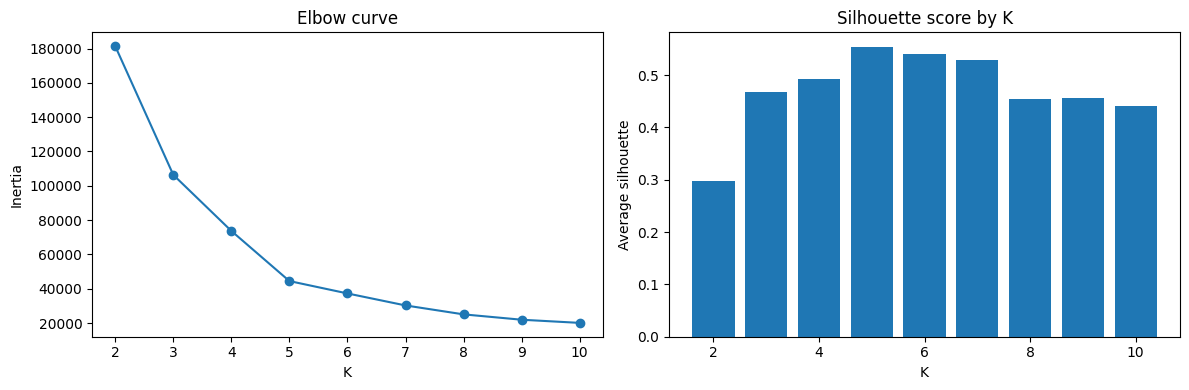

In [7]:
# YOUR CODE HERE
results = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    results.append((k, km.inertia_, silhouette_score(X2, km.labels_)))

res = pd.DataFrame(results, columns=['K', 'Inertia', 'Silhouette'])
res['Inertia'] = res['Inertia'].round(1)
res['Silhouette'] = res['Silhouette'].round(4)
print(res.to_string(index=False))

best_k = int(res.loc[res['Silhouette'].idxmax(), 'K'])
print('\nK with the highest silhouette:', best_k)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(res['K'], res['Inertia'], marker='o')
ax[0].set_xlabel('K')
ax[0].set_ylabel('Inertia')
ax[0].set_title('Elbow curve')

ax[1].bar(res['K'], res['Silhouette'])
ax[1].set_xlabel('K')
ax[1].set_ylabel('Average silhouette')
ax[1].set_title('Silhouette score by K')

plt.tight_layout()
plt.show()

Inertia falls at every step, as expected, but the drop shrinks sharply after K = 5:
from K=4 to K=5 it falls by about 29,231 (73,679.8 to 44,448.5), while from K=5 to
K=6 it falls by only about 7,215 (44,448.5 to 37,233.8), and later drops are
smaller still. The elbow is therefore at K = 5. The average silhouette is highest
at K = 5 (0.5539), then 0.5398 at K = 6 and 0.5288 at K = 7, and it is lowest at
K = 2 (0.2969). Both tools point to K = 5.

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point, using only NumPy distances. Apply it to customer 1 (row 0) and compare with `silhouette_samples`.

In [8]:
# YOUR CODE HERE
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
labels5 = km5.labels_

def silhouette_one(X, labels, i):
    d = np.sqrt(((X - X[i]) ** 2).sum(axis=1))      # distance from point i to every point
    own = labels[i]

    same = (labels == own)
    same[i] = False                                  # exclude the point itself
    a = d[same].mean()                               # average distance inside own cluster

    other_means = {k: d[labels == k].mean() for k in np.unique(labels) if k != own}
    nearest = min(other_means, key=other_means.get)
    b = other_means[nearest]                         # average distance to the nearest other cluster

    s = (b - a) / max(a, b)
    return a, b, s, own, nearest

a, b, s, own, nearest = silhouette_one(X2, labels5, 0)
sk = silhouette_samples(X2, labels5)[0]

print('Customer 1 (row 0): Income =', X2[0, 0], ', Spending =', X2[0, 1])
print('Own cluster:', own, '| nearest other cluster:', nearest)
print('a =', round(a, 4))
print('b =', round(b, 4))
print('s (by hand)            =', round(s, 4))
print('s (silhouette_samples) =', round(sk, 4))
print('Match:', np.isclose(s, sk))

Customer 1 (row 0): Income = 15 , Spending = 39
Own cluster: 4 | nearest other cluster: 0
a = 24.6404
b = 42.2653
s (by hand)            = 0.417
s (silhouette_samples) = 0.417
Match: True


My NumPy function gives a = 24.6404, b = 42.2653 and s = 0.417 for customer 1
(Income 15, Spending 39), which equals silhouette_samples (0.417). So the hand
calculation is correct.

**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote your numbers.

(b) What is the silhouette of customer 1, and what does it tell you about where that customer sits?

(c) Why should we never choose K only by the lowest inertia?

**Your answers:**

(a) The elbow suggests K = 5: inertia drops by about 29,231 from K=4 to K=5
(73,679.8 to 44,448.5) but only by about 7,215 from K=5 to K=6 (to 37,233.8),
so the curve bends at 5. The silhouette also suggests K = 5, because its highest
average value is 0.5539 at K = 5 (K=6: 0.5398, K=7: 0.5288). Yes, the two methods
agree, which makes K = 5 a well supported choice. It also matches the five groups
I saw by eye in the scatter plot in Part 0.

(b) For customer 1 (Income = 15, Spending = 39), a = 24.64 is the average distance to
the other points in its own cluster and b = 42.27 is the average distance to the
points of the nearest other cluster. So s = (42.27 - 24.64) / 42.27 = 0.417.
The value is clearly positive, so the customer is in the right cluster, because it
is much closer to its own cluster than to the next one. But 0.417 is lower than
the overall average silhouette for K = 5 (0.5539) and far from 1, so this customer
is not at the core of its group. It sits toward the edge of its cluster, at the
far left of the plot (the lowest income values), closer to the border with the
neighbouring cluster than a typical customer.

(c) Inertia always decreases as K grows (181,363.6 at K=2 down to 20,072.1 at
K=10), and it would reach 0 if K equalled the number of customers, with every
point as its own cluster. So the lowest inertia always picks the largest K, which
only overfits and gives useless segments. Inertia measures only how tight the
clusters are, not whether the groups are well separated or meaningful. That is why
we look for the elbow and also check the silhouette, which got worse after K = 5
(0.4411 at K=10).

---

## Part 3 — Starting Points and Stability (15 minutes)

The lecture said 'starting points matter — run several starts and keep the best'. Here you measure how much.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |

### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in two settings: `init='random'` with `n_init=1`, and `init='k-means++'` with `n_init=10`.
2. For each setting print the lowest and the highest final inertia and the number of distinct values (round to 1 decimal).

In [9]:
# YOUR CODE HERE
inertia_random = []
inertia_pp = []

for seed in range(30):
    km_r = KMeans(n_clusters=5, init='random', n_init=1, random_state=seed).fit(X2)
    inertia_random.append(km_r.inertia_)

    km_p = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=seed).fit(X2)
    inertia_pp.append(km_p.inertia_)

for name, vals in [("init='random', n_init=1", inertia_random),
                   ("init='k-means++', n_init=10", inertia_pp)]:
    rounded = np.round(vals, 1)
    best = rounded.min()
    print(name)
    print('  lowest inertia :', rounded.min())
    print('  highest inertia:', rounded.max())
    print('  distinct values:', len(np.unique(rounded)))
    print('  runs that reached the lowest value:', (rounded == best).sum(), 'of 30')
    print('  all distinct values:', np.unique(rounded))
    print()

init='random', n_init=1
  lowest inertia : 44448.5
  highest inertia: 91762.0
  distinct values: 14
  runs that reached the lowest value: 10 of 30
  all distinct values: [44448.5 44454.5 66532.  66674.4 66698.1 66733.4 66790.3 67789.3 67818.5
 70096.4 75036.5 75582.7 89897.5 91762. ]

init='k-means++', n_init=10
  lowest inertia : 44448.5
  highest inertia: 44448.5
  distinct values: 1
  runs that reached the lowest value: 30 of 30
  all distinct values: [44448.5]



**Questions** (answer with your own numbers)

(a) How many different final inertia values did each setting produce?

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init solve this problem? Use your numbers.

**Your answers:**

(a) init='random' with n_init=1 produced 14 different final inertia values
(lowest 44,448.5, highest 91,762.0), and only 10 of the 30 runs reached the
lowest one. init='k-means++' with n_init=10 produced only 1 value, 44,448.5,
in all 30 runs.

(b) K-Means depends on where the centroids start. The assign/update loop only
improves the solution step by step and stops at the first point where nothing
changes, which is a local minimum, not necessarily the best one. If two
starting centroids land in the same group of customers, or one lands far from
the data, the algorithm settles into a worse arrangement. With random starts,
different seeds give different starting points, so the same data and the same K
can end with different clusters and different inertia (for example 66,532.0 or
91,762.0 instead of 44,448.5).


(c) k-means++ chooses the starting centroids so that they are far apart from each
other, which avoids many bad starts. n_init repeats the whole algorithm several
times from different starts and keeps the run with the lowest inertia. In my
results, plain random starts reached the best inertia (44,448.5) in only 10 of 30
runs and sometimes ended as high as 91,762.0, while k-means++ with n_init=10
reached 44,448.5 in 30 of 30 runs. That is why I use n_init=10 for every model
in this lab.

---

## Part 4 — Scaling: Units Decide the Clusters (20 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it by changing only the unit of Income.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |

### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, `n_init=10`, `random_state=SEED`).
2. Print the ARI between raw k$ and raw dollars, and between scaled k$ and scaled dollars.
3. Draw Age vs Income (in k$) twice: coloured by the raw-dollar clusters and by the scaled clusters.

In [10]:
# YOUR CODE HERE
X_k = df[['Age', 'Income']].values.astype(float)    # Income in k$
X_d = X_k.copy()
X_d[:, 1] = X_d[:, 1] * 1000                         # Income in dollars

def cluster(X):
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X).labels_

lab_raw_k = cluster(X_k)
lab_raw_d = cluster(X_d)
lab_sc_k  = cluster(StandardScaler().fit_transform(X_k))
lab_sc_d  = cluster(StandardScaler().fit_transform(X_d))

print('ARI raw k$ vs raw dollars    :', round(adjusted_rand_score(lab_raw_k, lab_raw_d), 4))
print('ARI scaled k$ vs scaled dollars:', round(adjusted_rand_score(lab_sc_k, lab_sc_d), 4))

ARI raw k$ vs raw dollars    : 0.4897
ARI scaled k$ vs scaled dollars: 1.0


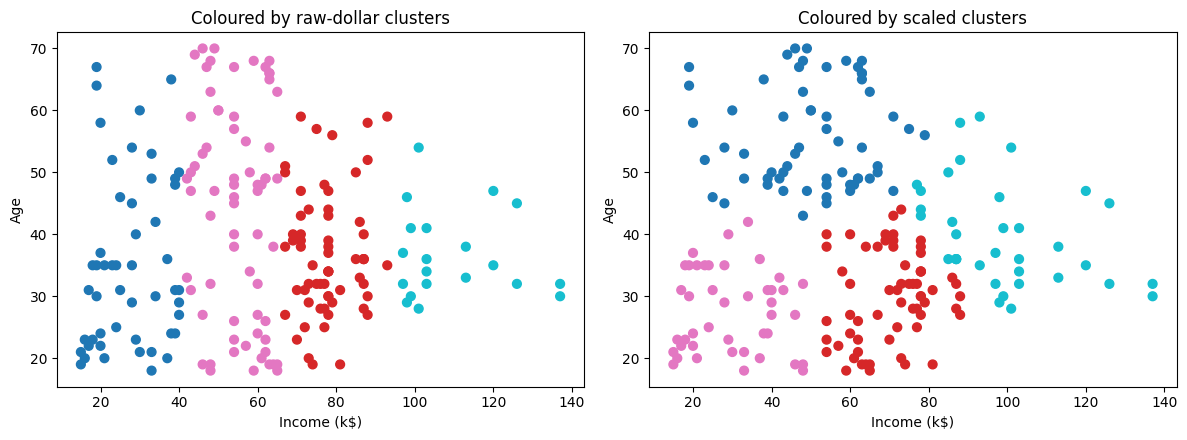

In [11]:
# YOUR CODE HERE
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].scatter(X_k[:, 1], X_k[:, 0], c=lab_raw_d, cmap='tab10', s=40)
ax[0].set_xlabel('Income (k$)')
ax[0].set_ylabel('Age')
ax[0].set_title('Coloured by raw-dollar clusters')

ax[1].scatter(X_k[:, 1], X_k[:, 0], c=lab_sc_k, cmap='tab10', s=40)
ax[1].set_xlabel('Income (k$)')
ax[1].set_ylabel('Age')
ax[1].set_title('Coloured by scaled clusters')

plt.tight_layout()
plt.show()

In the plot, the raw-dollar clusters are mostly vertical bands along the Income
axis and almost ignore Age, while the scaled clusters use both Age and Income
(for example, older customers with mid income form their own group).

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula: which feature controls the distance now? What did scaling fix?

(b) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.

**Your answers:**

(a) K-Means uses Euclidean distance, d = sqrt((ΔAge)² + (ΔIncome)²). When Income
is in dollars, a difference of 10 k$ becomes 10,000, so (ΔIncome)² is about
100,000,000 while (Δ Age)² for a 10-year gap is only 100. Income completely
controls the distance and Age has almost no effect, so the clustering becomes
essentially a split of Income alone. That is why the clusters changed (ARI = 0.4897
between raw k$ and raw dollars) even though no customer changed. In k$ the two
features were already unequal (Income std about 26.3, Age std about 14.0), so Income
had more weight there too, but much less than in dollars. Scaling fixed this:
StandardScaler turns every column into z = (x - mean) / std, so Age and Income both
have mean 0 and std 1 and contribute equally. The z-scores do not depend on the
unit, so scaled k$ and scaled dollars give the same data and the same clusters
(ARI = 1.0).

(b) My rule: scale whenever the features are in different units or have very
different ranges, because K-Means is based on distances and the feature with the
largest numbers would dominate. I would skip scaling only when all features share
the same unit and a similar range, and the raw differences are meaningful.

---

## Part 5 — Outliers (15 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and catch it with a simple distance rule.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |

### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (`n_init=10`, `random_state=SEED`) without and with the extra customer.
2. Print the cluster sizes and the centroids (sorted by income) for both fits.
3. Draw the two clusterings side by side.

Without the extra customer (200 rows)
  size =  22 | centroid Income =   25.73, Spending =  79.36
  size =  23 | centroid Income =   26.30, Spending =  20.91
  size =  81 | centroid Income =   55.30, Spending =  49.52
  size =  39 | centroid Income =   86.54, Spending =  82.13
  size =  35 | centroid Income =   88.20, Spending =  17.11

With the extra customer (201 rows)
  size =  23 | centroid Income =   26.30, Spending =  20.91
  size = 100 | centroid Income =   48.26, Spending =  56.48
  size =  39 | centroid Income =   86.54, Spending =  82.13
  size =  38 | centroid Income =   87.00, Spending =  18.63
  size =   1 | centroid Income =  400.00, Spending =  99.00



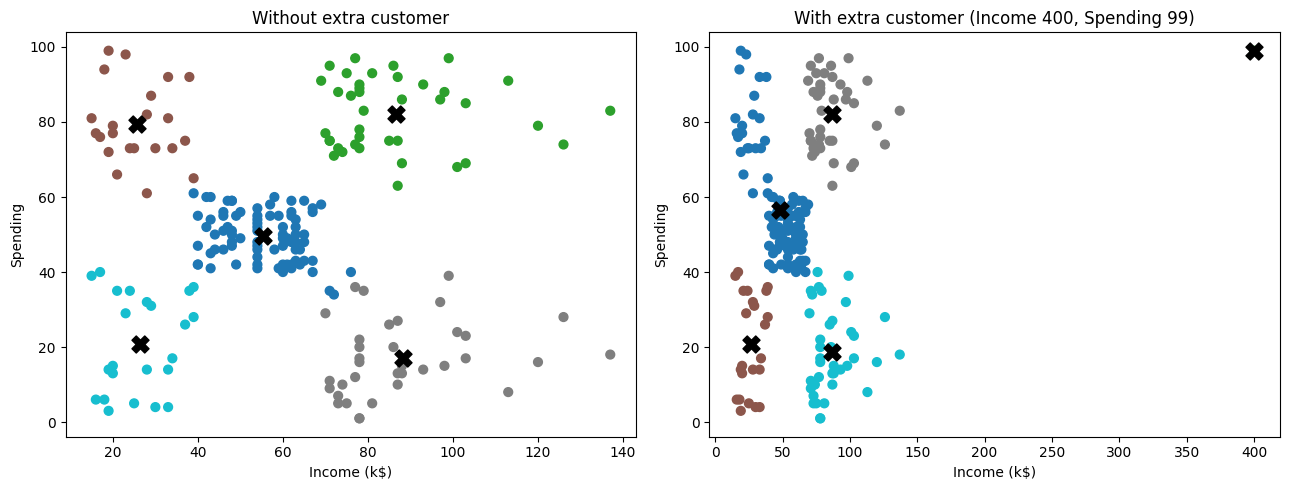

In [12]:
# YOUR CODE HERE
X2 = df[['Income', 'Spending']].values.astype(float)
X_out = np.vstack([X2, [400, 99]])                  # 201 rows, last one is the extra customer

model_orig = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
model_out  = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_out)

def show(model, title):
    order = np.argsort(model.cluster_centers_[:, 0])         # sort clusters by income
    sizes = np.bincount(model.labels_, minlength=5)
    print(title)
    for k in order:
        c = model.cluster_centers_[k]
        print(f'  size = {sizes[k]:3d} | centroid Income = {c[0]:7.2f}, Spending = {c[1]:6.2f}')
    print()

show(model_orig, 'Without the extra customer (200 rows)')
show(model_out,  'With the extra customer (201 rows)')

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].scatter(X2[:, 0], X2[:, 1], c=model_orig.labels_, cmap='tab10', s=40)
ax[0].scatter(model_orig.cluster_centers_[:, 0], model_orig.cluster_centers_[:, 1],
              c='black', marker='X', s=150)
ax[0].set_title('Without extra customer')

ax[1].scatter(X_out[:, 0], X_out[:, 1], c=model_out.labels_, cmap='tab10', s=40)
ax[1].scatter(model_out.cluster_centers_[:, 0], model_out.cluster_centers_[:, 1],
              c='black', marker='X', s=150)
ax[1].set_title('With extra customer (Income 400, Spending 99)')

for a in ax:
    a.set_xlabel('Income (k$)')
    a.set_ylabel('Spending')

plt.tight_layout()
plt.show()

Without the extra customer, the 5 clusters have sizes 22, 23, 81, 39 and 35 and
match the five groups seen in Part 0. With the one extra customer (Income 400,
Spending 99), the sizes become 23, 100, 39, 38 and 1. The extra customer takes a
cluster of its own (centroid at Income 400, Spending 99), and the 4 remaining
centroids have to describe the 200 real customers, so two real groups are merged
into one cluster of 100 customers.

### Task 5.2 — Catch it with a distance rule

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). Is the extra customer flagged? Are any real customers flagged?

In [13]:
# YOUR CODE HERE
# distance of every real customer to its nearest centroid (model fitted on the original 200)
d_orig = model_orig.transform(X2).min(axis=1)

mean_d = d_orig.mean()
std_d = d_orig.std()
threshold = mean_d + 3 * std_d

# distance of the extra customer to the nearest centroid of the same model
d_extra = model_orig.transform(np.array([[400.0, 99.0]])).min(axis=1)[0]

print('Mean distance (200 real customers):', round(mean_d, 2))
print('Std of distance                   :', round(std_d, 2))
print('Threshold (mean + 3 std)          :', round(threshold, 2))
print()
print('Extra customer distance           :', round(d_extra, 2))
print('Extra customer flagged            :', d_extra > threshold)
print()

flagged_real = np.where(d_orig > threshold)[0]
print('Real customers flagged            :', len(flagged_real))
if len(flagged_real) > 0:
    print(df.loc[flagged_real, ['CustomerID', 'Income', 'Spending']].assign(
        distance=np.round(d_orig[flagged_real], 2)).to_string(index=False))

Mean distance (200 real customers): 13.02
Std of distance                   : 7.26
Threshold (mean + 3 std)          : 34.8

Extra customer distance           : 313.92
Extra customer flagged            : True

Real customers flagged            : 4
 CustomerID  Income  Spending  distance
        197     126        28     39.34
        198     126        74     40.29
        199     137        18     48.81
        200     137        83     50.47


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Use the sizes and centroids.

(b) Did the rule catch the extra customer? If real customers were flagged too, are they errors or simply unusual customers?

(c) Name two ways to deal with outliers and one risk of simply deleting them.

**Your answers:**

(a) One extra customer changed the whole clustering. Without it the sizes were
22, 23, 81, 39 and 35. With it, one cluster contains only that customer (size 1,
centroid at Income 400, Spending 99), so one of the five clusters is wasted on a
single point. That leaves 4 clusters for the 200 real customers, and K-Means
merged the "low income, high spending" group (22 customers, centroid
25.73 / 79.36) with the "average" group (81 customers, centroid 55.30 / 49.52)
into one cluster of 100 customers with centroid 48.26 / 56.48. That centroid is
not a real group of customers: it sits between two different segments. The
bottom-right cluster also changed (35 to 38 customers, centroid from
88.20 / 17.11 to 87.00 / 18.63), while the clusters at 26.30 / 20.91 (23
customers) and 86.54 / 82.13 (39 customers) stayed the same. This happens
because K-Means uses means and squared distances, so one far point has a very
large effect on the clustering.


(b) Yes, the rule caught the extra customer: its distance to the nearest centroid
is 313.92, much larger than the threshold of 34.80. It also flagged 4 real
customers (197, 198, 199, 200) with distances between 39.34 and 50.47. They are
not errors, they are simply unusual customers: their incomes (126 and 137 k$) are
the highest in the dataset, at the far right edge of the high-income clusters,
with realistic Spending scores (28, 74, 18, 83). They are far from their
centroids only because they sit at the extreme end of a real group. This also
shows a limit of the rule: it is a simple distance cut-off, so it flags
legitimate extreme customers as well as real outliers, and the flagged points
should be looked at before anything is done with them.

(c) Two ways to deal with outliers: (1) remove or cap them (for example, delete
points flagged by the distance rule, or limit extreme values to a maximum), and
(2) use a method that is less sensitive to outliers, such as K-Medoids or
DBSCAN, or give flagged points their own separate group instead of forcing them
into a normal segment. One risk of simply deleting them is losing real and
possibly valuable customers: customers 197-200 are genuine high-income shoppers,
so removing them would hide part of the high-income segments and bias the
results. Deleting also hides the problem instead of understanding it, and the
rule could remove real data just because it is unusual.

---

## Part 6 — Name the Segments and Wrap-Up (20 minutes)

Turn your clusters into segments that a marketing team could use.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Segment profile | The average Age, Income and Spending of each cluster. It tells you who is in the group. | `df.groupby('Cluster')[['Age','Income','Spending']].mean()` |
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |

### Task 6.1 — Profile and name the segments

Use the K you chose in Part 2 and the Income and Spending features.

1. Fit the final model (`n_init=10`, `random_state=SEED`) and add a Cluster column to the DataFrame.
2. Show the size and the mean Age, Income and Spending of each cluster.
3. Give each cluster a short name (e.g. 'High income, low spending') and one marketing action. Store the name in a Segment column.

In [14]:
# YOUR CODE HERE
X2 = df[['Income', 'Spending']].values.astype(float)

final_model = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
df['Cluster'] = final_model.labels_

cols = ['Age', 'Income', 'Spending']
profile = df.groupby('Cluster')[cols].mean().round(2)
profile.insert(0, 'Size', df['Cluster'].value_counts().sort_index())
print(profile)

         Size    Age  Income  Spending
Cluster                               
0          81  42.72   55.30     49.52
1          39  32.69   86.54     82.13
2          22  25.27   25.73     79.36
3          35  41.11   88.20     17.11
4          23  45.22   26.30     20.91


In [15]:
segment_names = {
    0: 'Average income, average spending',
    1: 'High income, high spending',
    2: 'Low income, high spending',
    3: 'High income, low spending',
    4: 'Low income, low spending',
}
df['Segment'] = df['Cluster'].map(segment_names)

print(df.groupby(['Cluster', 'Segment']).size())

Cluster  Segment                         
0        Average income, average spending    81
1        High income, high spending          39
2        Low income, high spending           22
3        High income, low spending           35
4        Low income, low spending            23
dtype: int64


The five clusters have sizes 81, 39, 22, 35 and 23. The largest (81 customers) is
the average-income, average-spending group. The two high-income groups have
similar incomes (86.54 and 88.20 k$) but very different spending (82.13 vs 17.11).
The high-spending groups are younger (average age 32.69 and 25.27) than the
low-spending groups (41.11 and 45.22).

**Segment names and actions** (one line per cluster)

| Cluster | Segment name | Marketing action |
|---|---|---|
| 0 | Average income, average spending | Loyalty points and seasonal discounts |
| 1 | High income, high spending | Premium membership and early access to new products |
| 2 | Low income, high spending | Affordable trendy products and student offers |
| 3 | High income, low spending | Personalised offers and premium ranges to raise their spending |
| 4 | Low income, low spending | Low-cost basics and clearance sales |

### Task 6.2 — Save and summarise

Produce a file someone else can use without running your notebook.

1. Save `customer_segments.csv` with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.
2. Write a 4–6 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, how you handled scaling and outliers, and one limitation.

In [16]:
# YOUR CODE HERE
out = df[['CustomerID', 'Age', 'Gender', 'Income', 'Spending', 'Cluster', 'Segment']]
out.to_csv('customer_segments.csv', index=False)

print(out.shape)
out.head()

(200, 7)


,CustomerID,Age,Gender,Income,Spending,Cluster,Segment
0,1,19,Male,15,39,4,"Low income, low spending"
1,2,21,Male,15,81,2,"Low income, high spending"
2,3,20,Female,16,6,4,"Low income, low spending"
3,4,23,Female,16,77,2,"Low income, high spending"
4,5,31,Female,17,40,4,"Low income, low spending"


**Executive Summary** (4–6 lines)

- **K = 5.** The elbow bends at K = 5 (inertia drop 29,231 from K=4 to 5, then only 7,215 to K=6) and the silhouette peaks at 0.5539 at K = 5.
- **Segments:** average income/average spending (81), high income/high spending (39), high income/low spending (35), low income/low spending (23), low income/high spending (22).
- **Scaling:** Income and Spending have similar ranges and spreads (std 26.3 and 25.8), so I used them unscaled. Part 4 showed scaling is needed when units differ (ARI 0.4897 unscaled vs 1.0 scaled).
- **Outliers:** one extreme customer (400, 99) broke the clusters in Part 5. The mean + 3 std rule caught it and also flagged 4 real high-income customers (126-137 k$), which I kept.
- **Limitation:** only 200 customers and two features, so Age and Gender are ignored and customers near the borders between segments, like customer 1 (silhouette 0.417), can be assigned loosely.

---

### Before you submit
- [ ] Restart the kernel and **Run All**: the notebook runs top to bottom without errors.
- [ ] Every table and plot has 1–3 lines of interpretation below it.
- [ ] All questions are answered with your own numbers.
- [ ] Student Information block is filled in.
- [ ] Notebook and `customer_segments.csv` are pushed to your GitHub repository.